# Batch correction with totalVI (joint RNA + protein)

totalVI (Gayoso *et al.*, *Nat Methods* 2021) is a joint generative model of
CITE-seq data: RNA counts and antibody-derived tag (ADT) counts share one
latent space; protein counts are modelled as a mixture of a background and a
foreground component, so the model also returns **denoised** protein
expression. Batch is a decoder covariate, as in scVI.


> **Backend.** Since omicverse 2.4 the scVI family (`'scVI'`, `'scANVI'`,
> `'totalVI'`) runs on **`ov.vi`** — omicverse's own PyTorch implementation
> (scvi-tools-compatible API and defaults, no scvi-tools / Lightning
> dependency). It trains on in-memory AnnData, disk-backed AnnDataOOM
> (`ov.read(path, storage='disk')`) and Dask-backed AnnData (GPU mode). See
> [t_vi](../t_vi.ipynb) for the direct `ov.vi` API, disk and GPU training.


This is one of the **omicverse batch-correction zoo** tutorials. See
[batch/index](../index.md) for the overview / decision tree, or
[../t_single_batch](../t_single_batch.ipynb) for the side-by-side comparison of
every backend.

## Load a real CITE-seq dataset with two batches

`ov.datasets.cite_seq()` downloads two public 10x Genomics PBMC CITE-seq runs
(`pbmc_10k_protein_v3` and `5k_pbmc_protein_v3`, TotalSeq-B panels), filtered
for doublets and outliers as in the totalVI paper — the same data as
scvi-tools' `pbmcs_10x_cite_seq`, without needing scvi-tools. The two runs are
the batches (`obs['batch']`: `PBMC10k`, `PBMC5k`); raw RNA counts are in `X` /
`layers['counts']` and the 14 antibodies measured in both runs in
`obsm['protein_expression']`. All 10 849 cells are used.

In [1]:
import omicverse as ov
import numpy as np
import pandas as pd
ov.style()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…


✅ NVIDIA CUDA GPUs detected: 1
    • [CUDA 0] NVIDIA H100 80GB HBM3
      Memory: 79.1 GB | Compute: 9.0

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: unknown   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
adata = ov.datasets.cite_seq()
adata

Loading 10x PBMC CITE-seq (5k + 10k)
⚠️ File ./data/pbmc_10k_protein_v3.h5ad already exists


⚠️ File ./data/pbmc_5k_protein_v3.h5ad already exists


✅ 10849 cells x 15792 genes, 14 proteins


AnnData object with n_obs × n_vars = 10849 × 15792
    obs: 'n_genes', 'percent_mito', 'n_counts', 'batch'
    uns: 'protein_names'
    obsm: 'protein_expression'
    layers: None (.X), 'counts'

In [3]:
adata.obsm['protein_expression'].iloc[:3, :8]

                            CD3_TotalSeqB  CD4_TotalSeqB  CD8a_TotalSeqB  \
index                                                                      
AAACCCAAGATTGTGA-1-PBMC10k           18.0          138.0            13.0   
AAACCCACATCGGTTA-1-PBMC10k           30.0          119.0            19.0   
AAACCCAGTACCGCGT-1-PBMC10k           18.0          207.0            10.0   

                            CD14_TotalSeqB  CD15_TotalSeqB  CD16_TotalSeqB  \
index                                                                        
AAACCCAAGATTGTGA-1-PBMC10k           491.0            61.0            17.0   
AAACCCACATCGGTTA-1-PBMC10k           472.0           102.0           155.0   
AAACCCAGTACCGCGT-1-PBMC10k          1289.0           128.0            72.0   

                            CD56_TotalSeqB  CD19_TotalSeqB  
index                                                       
AAACCCAAGATTGTGA-1-PBMC10k            17.0             3.0  
AAACCCACATCGGTTA-1-PBMC10k           248.0   

## Preprocess

QC → normalisation + log → 2 000 HVGs → scaled PCA, with the raw counts kept
in `layers['counts']`. The protein matrix in `obsm` follows every cell subset.
The dataset has no cell-type annotation; we read cell identity from the
proteins below.

In [4]:
adata = ov.pp.qc(adata, tresh={'mito_perc': 0.2, 'nUMIs': 500, 'detected_genes': 250},
                 doublets=False)
adata = ov.pp.preprocess(adata, mode='shiftlog|pearson', n_HVGs=2000)

🖥️ Using CPU mode for QC...
   Auto-detected mitochondrial prefix: 'MT-'

📊 Step 1: Calculating QC Metrics

   ✓ Gene Family Detection:
   ┌──────────────────────────────┬────────────────────┬────────────────────┐
   │ Gene Family                  │ Genes Found        │ Detection Method   │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Mitochondrial                │ 13                 │ Auto (MT-)         │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Ribosomal                    │ 95                 │ Auto (RPS/RPL)     │
   ├──────────────────────────────┼────────────────────┼────────────────────┤
   │ Hemoglobin                   │ 6                  │ Auto (regex)       │
   └──────────────────────────────┴────────────────────┴────────────────────┘

   ✓ QC Metrics Summary:
   ┌─────────────────────────┬────────────────────┬─────────────────────────┐
   │ Metric                  │ Mean               │ Range 

   ✓ Final filtering: 0 cells, 0 genes removed

📊 Step 4: Doublet detection disabled

╭─ SUMMARY: qc ──────────────────────────────────────────────────────╮
│  Duration: 0.6449s                                                 │
│  Shape:    10,849 x 15,792 (Unchanged)                             │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBS    │ ✚ cell_complexity (float)                              │
│           │ ✚ detected_genes (int)                                 │
│           │ ✚ hb_perc (float)                                      │
│           │ ✚ mito_perc (float)                                    │
│           │ ✚ nUMIs (float)                                        │
│           │ ✚ n_genes_by_counts (int)                              │
│           │ ✚ passing_mt (bool)                             

   ⚠️ Excluding 4 highly-expressed genes from normalization computation
   Excluded genes: ['IGKC', 'MALAT1', 'IGLC2', 'IGLC3']

✅ Count Normalization Completed Successfully!
   ✓ Processed: 10,848 cells × 15,792 genes
   ✓ Runtime: 0.18s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 15,792 total (12.7%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 1.27 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ───────────────────

In [5]:
adata.raw = adata
adata = adata[:, adata.var.highly_variable_features].copy()
ov.pp.scale(adata)
ov.pp.pca(adata, layer='scaled', n_pcs=30)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.054s                                                  │
│  Shape:    10,848 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 10848x2000)                           │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=30
   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (10848, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (1.93s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 1.9358s                                                 │
│  Shape:    10,848 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 10848x30)                              │
│           │ ✚ scaled|original|X_pca (array, 10848x30)              │
│         

## Uncorrected baseline

The two 10x runs separate on the uncorrected RNA UMAP:

🖥️ Using Scanpy CPU to calculate neighbors...

🔍 K-Nearest Neighbors Graph Construction:
   Mode: cpu
   Neighbors: 15
   Method: umap
   Metric: euclidean
   Representation: scaled|original|X_pca
   🔍 Computing neighbor distances...


   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity
   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 10,848 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 0.817s                                                  │
│  Shape:    10,848 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 15, 'method': 'umap', 'random_s...│
│                       

   🔍 Computing UMAP parameters...
   🔍 Computing UMAP embedding (classic method)...



✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 10,848 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 7.0042s                                                 │
│  Shape:    10,848 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': np.float64(0.5830300203414425), 'b': np.f...│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 10848x2)                              │
│                

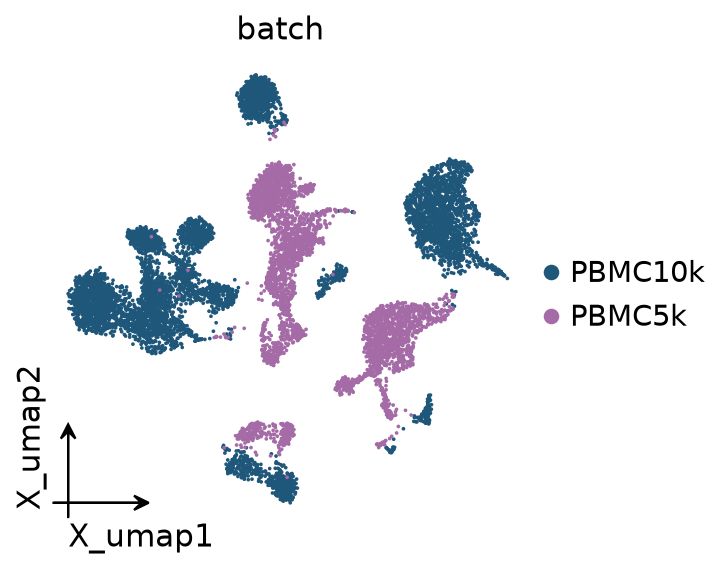

In [6]:
ov.pp.neighbors(adata, use_rep='scaled|original|X_pca', n_neighbors=15)
ov.pp.umap(adata)
ov.pl.embedding(adata, basis='X_umap', color=['batch'], frameon='small')

## Run `ov.single.batch_correction(methods='totalVI')`

totalVI needs raw RNA counts (`layers['counts']`) and the raw protein matrix in
the `obsm` slot named by `protein_expression_obsm_key`. Everything else is left
at the totalVI defaults (20-d latent; lr 4e-3, batch 256, early stopping and
LR reduction on the validation ELBO, checked every epoch).

In [7]:
model = ov.single.batch_correction(adata, batch_key='batch', methods='totalVI',
                                   protein_expression_obsm_key='protein_expression')
model

...Begin using totalVI to correct batch effect


Training:   0%|          | 0/400 [00:00<?, ?epoch/s]


╭─ SUMMARY: batch_correction ────────────────────────────────────────╮
│  Duration: 41.4129s                                                │
│  Shape:    10,848 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● OBSM   │ ✚ X_totalVI (array, 10848x20)                          │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯


TOTALVI(n_obs=10848, n_vars=2000, n_batch=2, n_labels=1, layer='counts', trained=True)

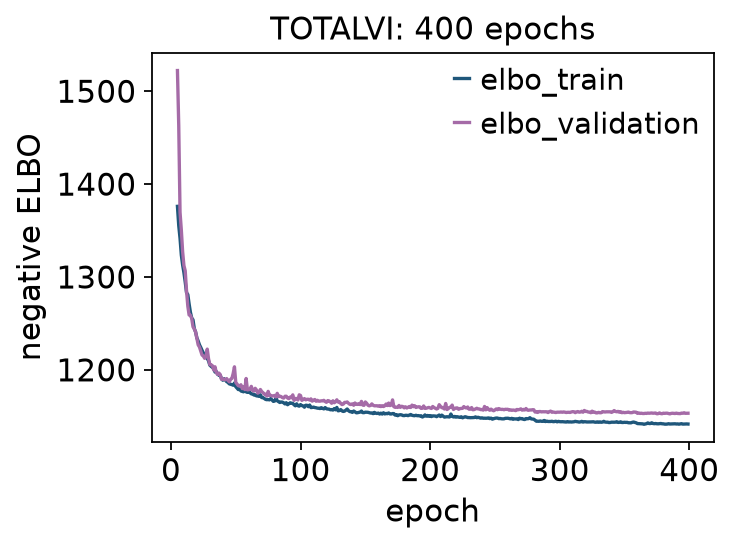

In [8]:
ov.vi.plot_history(model, skip_first=5);

## Corrected embedding and clusters

MDE of the joint latent coloured by run, plus Leiden clusters computed on the
totalVI latent:

🖥️ Using Scanpy CPU to calculate neighbors...

🔍 K-Nearest Neighbors Graph Construction:
   Mode: cpu
   Neighbors: 15
   Method: umap
   Metric: euclidean
   Representation: X_totalVI
   🔍 Computing neighbor distances...


   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity
   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 10,848 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 0.337s                                                  │
│  Shape:    10,848 x 2,000 (Unchanged)                              │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
╰────────────────────────────────────────────────────────────────────╯
🖥️ Using Scanpy CPU Leiden...
running Leiden clustering
    finished (0.03s)
    found 16 clusters an

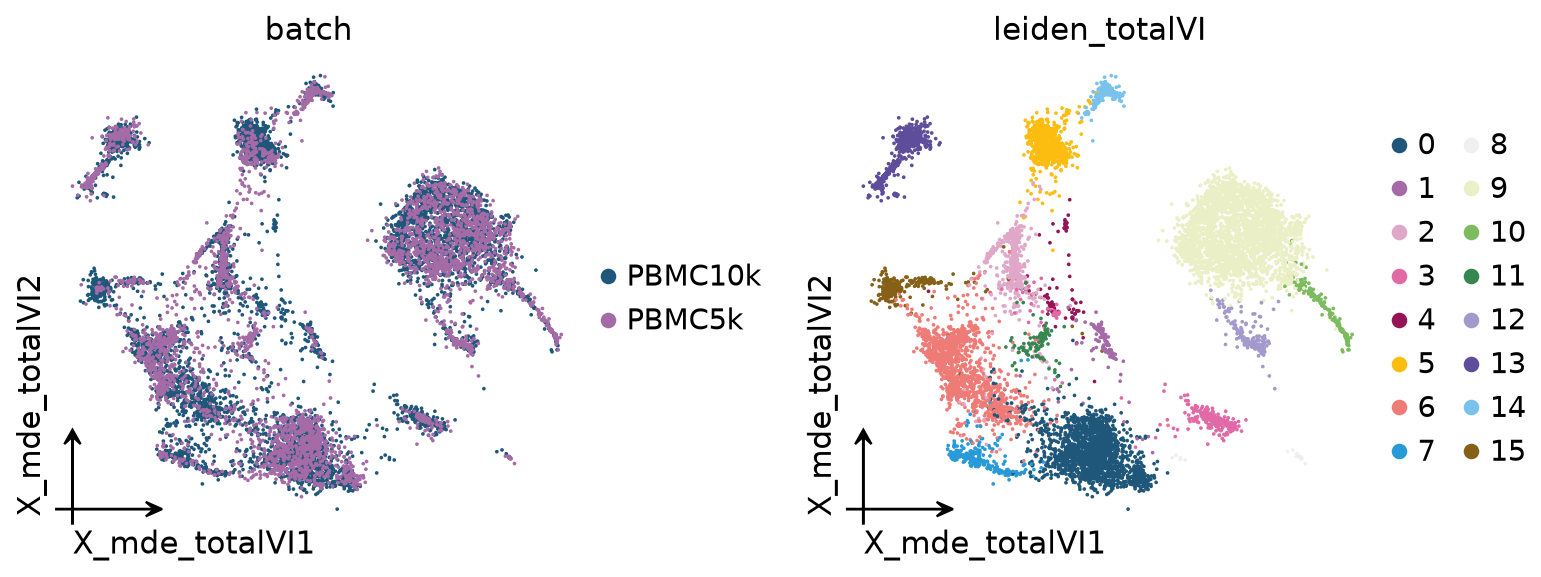

In [9]:
adata.obsm['X_mde_totalVI'] = ov.vi.mde(adata.obsm['X_totalVI'])
ov.pp.neighbors(adata, use_rep='X_totalVI', n_neighbors=15)
ov.pp.leiden(adata, resolution=0.6, key_added='leiden_totalVI')
ov.pl.embedding(adata, basis='X_mde_totalVI', color=['batch', 'leiden_totalVI'],
                frameon='small', wspace=0.5)

Batch mixing on the latent, before vs. after (iLISI / kBET need a label per
cell; with no annotation we use the totalVI Leiden clusters, so only the
batch-removal columns are meaningful here):

In [10]:
scores = ov.vi.integration_metrics(adata, ['X_pca', 'X_totalVI'], batch_key='batch',
                                   label_key='leiden_totalVI', n_jobs=16, nmi_ari=False)
scores[['iLISI', 'kBET', 'ASW_batch']].round(3)

INFO     4 consists of a single batch or is too small. Skip.                                                       


INFO     4 consists of a single batch or is too small. Skip.                                                       


           iLISI   kBET  ASW_batch
embedding                         
X_pca      0.000  0.120      0.523
X_totalVI  0.546  0.594      0.899

## Denoised protein expression

`get_normalized_expression` returns denoised RNA and protein (foreground
only, background removed); 25 posterior samples are averaged. The marker
proteins should mark the expected lineages — CD3 (T), CD4 vs. CD8a (T
subsets), CD14 (classical monocytes), CD16 (non-classical monocytes / NK),
CD56 (NK), CD19 (B) — and look the same in both runs.

In [11]:
rna, protein = model.get_normalized_expression(n_samples=25)
markers = ['CD3_TotalSeqB', 'CD4_TotalSeqB', 'CD8a_TotalSeqB', 'CD14_TotalSeqB',
           'CD16_TotalSeqB', 'CD56_TotalSeqB', 'CD19_TotalSeqB', 'CD45RA_TotalSeqB']
adata.obs[[m.split('_')[0] for m in markers]] = np.log1p(protein[markers].values)

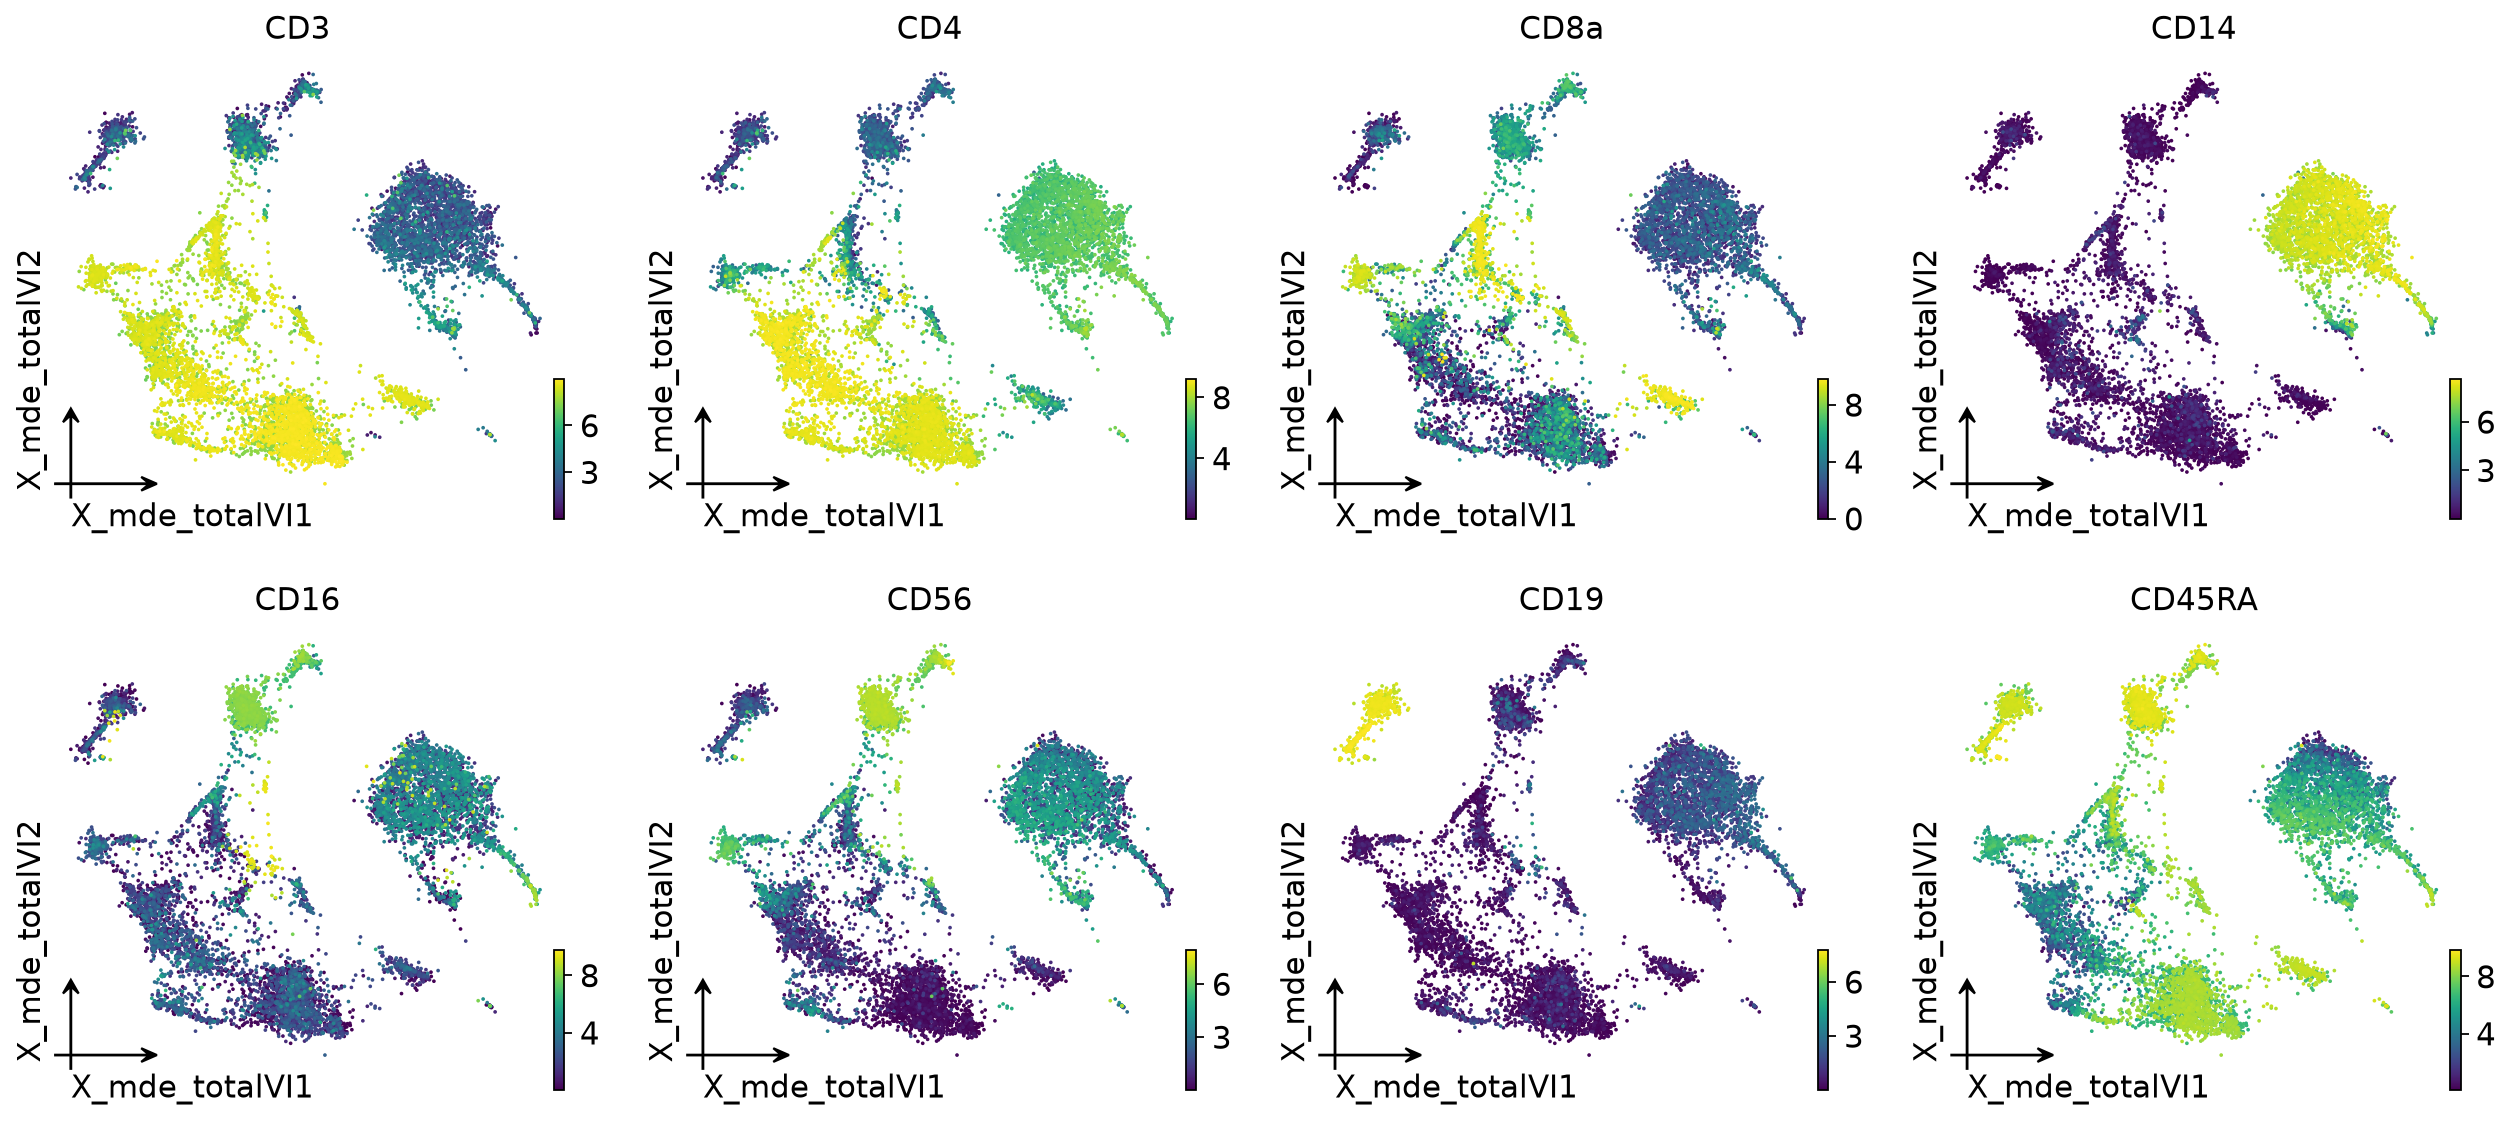

In [12]:
ov.pl.embedding(adata, basis='X_mde_totalVI', color=[m.split('_')[0] for m in markers],
                frameon='small', ncols=4, cmap='viridis')

Denoising keeps the signal: per-protein Pearson correlation between log raw
and log denoised counts (background removal lowers it most for weakly
expressed markers such as CD25 or PD-1).

In [13]:
raw = np.log1p(adata.obsm['protein_expression'][protein.columns].values)
r = [np.corrcoef(raw[:, j], np.log1p(protein.values[:, j]))[0, 1] for j in range(raw.shape[1])]
pd.Series(r, index=protein.columns).round(3).sort_values()

CD25_TotalSeqB      0.584
PD-1_TotalSeqB      0.585
TIGIT_TotalSeqB     0.688
CD56_TotalSeqB      0.754
CD8a_TotalSeqB      0.793
CD45RO_TotalSeqB    0.854
CD16_TotalSeqB      0.858
CD127_TotalSeqB     0.860
CD19_TotalSeqB      0.863
CD45RA_TotalSeqB    0.882
CD4_TotalSeqB       0.904
CD14_TotalSeqB      0.917
CD3_TotalSeqB       0.942
CD15_TotalSeqB      0.960
dtype: float64

## Key parameters

**Required**:
- `protein_expression_obsm_key` — `obsm` slot with the raw (cells × proteins)
  ADT counts (DataFrame, or array + `protein_names_uns_key`).

**Model** (→ `ov.vi.TOTALVI.__init__`; scvi-tools defaults):
- `n_latent` (20), `gene_likelihood` (`'nb'` or `'zinb'`),
  `gene_dispersion` (`'gene'`), `protein_dispersion` (`'protein'`),
  `latent_distribution` (`'normal'`).
- `empirical_protein_background_prior` (default: when > 10 proteins) — GMM
  initialisation of the protein background.
- `override_missing_proteins` (False) — proteins with all-zero counts in a
  batch are treated as missing there (e.g. `ov.datasets.cite_seq(protein_join='outer')`,
  29 proteins); an adversarial batch classifier is then switched on.
- covariate keys, `genes`, `seed` — as scVI.

**Training** (→ `TOTALVI.train`): `max_epochs` (scvi-tools heuristic),
`lr` (4e-3), `batch_size` (256), `early_stopping` (True),
`reduce_lr_on_plateau` (True), `n_steps_kl_warmup` (0.75 × n_cells),
`device`, `devices`.


**Routing.** `ov.single.batch_correction` builds the `ov.vi` model with
`layer='counts'` (when that layer exists) and `batch_key=`, sends every keyword
the model constructor accepts there and every training / optimisation keyword
(`max_epochs`, `lr`, `n_epochs_kl_warmup`, ...) to `.train()`. scvi-tools
spellings are translated: `accelerator='gpu'` → `device='cuda'`,
`use_gpu=`, `enable_progress_bar=` → `progress=`; Lightning-only options
(`logger`, `trainer_config`, ...) are dropped.


**Outputs**: `adata.obsm['X_totalVI']`; the returned model offers
`get_normalized_expression` (RNA + protein), `get_protein_foreground_probability`,
`get_latent_library_size`.

## Related tutorials

- [t_vi](../t_vi.ipynb) — the `ov.vi` API directly: in memory, from disk and on the GPU.
- [t_batch_scvi](t_batch_scvi.ipynb) — RNA only.
- [t_batch_scanvi](t_batch_scanvi.ipynb) — RNA + labels.

For the full side-by-side comparison with scib-metrics scoring, see
[../t_single_batch](../t_single_batch.ipynb).